In [1]:
import pandas as pd
import numpy as np

## Load Data

In [2]:
dataset=pd.read_csv("../data/Student_Performance.csv")

In [3]:
dataset.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [4]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [5]:
print(dataset.describe())

       Hours Studied  Previous Scores   Sleep Hours  \
count   10000.000000     10000.000000  10000.000000   
mean        4.992900        69.445700      6.530600   
std         2.589309        17.343152      1.695863   
min         1.000000        40.000000      4.000000   
25%         3.000000        54.000000      5.000000   
50%         5.000000        69.000000      7.000000   
75%         7.000000        85.000000      8.000000   
max         9.000000        99.000000      9.000000   

       Sample Question Papers Practiced  Performance Index  
count                      10000.000000       10000.000000  
mean                           4.583300          55.224800  
std                            2.867348          19.212558  
min                            0.000000          10.000000  
25%                            2.000000          40.000000  
50%                            5.000000          55.000000  
75%                            7.000000          71.000000  
max             

## Check Missing Values

In [6]:
print(dataset.isnull().sum())

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64


## Check Duplicated Values

In [7]:
print(dataset.duplicated().sum())

127


In [8]:
dup_rows = dataset[dataset.duplicated(keep=False)].sort_values(list(dataset.columns))
dup_rows.head(10)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
6975,1,41,No,7,3,12.0
9966,1,41,No,7,3,12.0
2225,1,42,Yes,9,7,17.0
4986,1,42,Yes,9,7,17.0
2647,1,57,No,8,0,31.0
8522,1,57,No,8,0,31.0
3398,1,63,Yes,8,3,37.0
8184,1,63,Yes,8,3,37.0
4573,1,66,No,8,2,40.0
5578,1,66,No,8,2,40.0


## Handling Duplicates

`dataset.duplicated().sum()` found **127 duplicated rows** (~1.3% of 10,000).

**Decision: drop them.**

- The dataset has no ID column, so I cannot tell whether a duplicate is a copied record or two different students with identical values.
- The features are small integers, so a few coincidental matches are plausible. Still, I can't verify that.
- Keeping duplicates risks the same row landing in both the train and test sets, which would make the evaluation slightly too optimistic (data leakage).
- Dropping ~1.3% of the data costs very little.

In [9]:
print("Before:", dataset.shape)
dataset = dataset.drop_duplicates().reset_index(drop=True)
print("After:", dataset.shape)

Before: (10000, 6)
After: (9873, 6)


## Correlation Analysis

Before building the model, I check how each numeric feature relates to the target `Performance Index`.

Correlation (r) is a number between -1 and +1: close to +1 means both values rise together, close to 0 means no clear linear relationship, and close to -1 means one rises while the other falls. It only measures *linear* relationships, so I also look at plots.

`Extracurricular Activities` is text (Yes/No), so it is not in the matrix. I analyze it separately below.

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
corr=dataset.corr(numeric_only=True)
corr

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
Hours Studied,1.000000,-0.010676,0.002131,0.015740,0.375332
Previous Scores,-0.010676,1.000000,0.007975,0.008719,0.915135
Sleep Hours,0.002131,0.007975,1.000000,0.004907,0.050352
Sample Question Papers Practiced,0.015740,0.008719,0.004907,1.000000,0.043436
Performance Index,0.375332,0.915135,0.050352,0.043436,1.000000


**Observation:** The strongest relationship with `Performance Index` is `Previous Scores` (r = 0.92), followed by `Hours Studied` (r = 0.38). `Sleep Hours` (r = 0.05) and `Sample Question Papers Practiced` (r = 0.04) are close to zero.

### Heatmap

The same matrix as colors (red = positive, blue = negative). The diagonal is 1 because each column is perfectly correlated with itself.

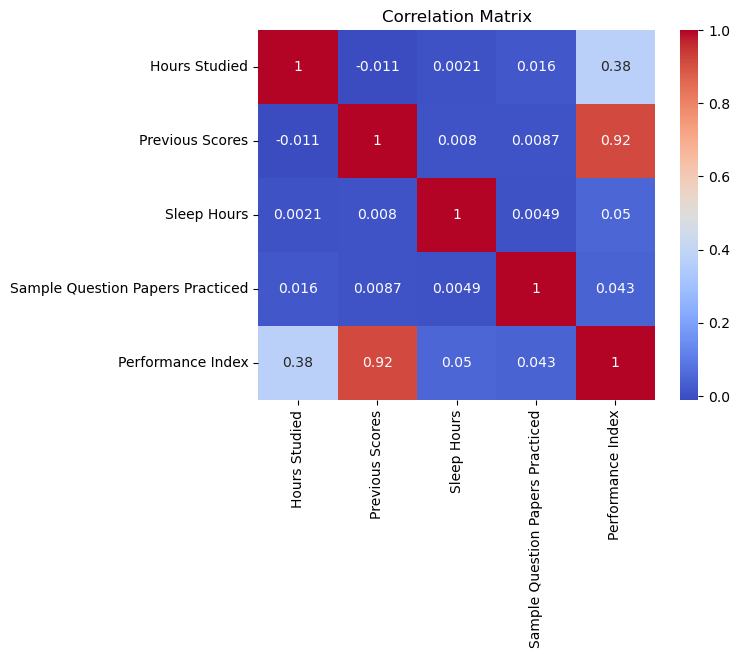

In [11]:
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

### Ranking by correlation with the target

| Feature | r with Performance Index |
|---|---|
| Previous Scores | 0.915 |
| Hours Studied | 0.375 |
| Sleep Hours | 0.050 |
| Sample Question Papers Practiced | 0.043 |

In [12]:
corr["Performance Index"].sort_values(ascending=False)

Performance Index                   1.000000
Previous Scores                     0.915135
Hours Studied                       0.375332
Sleep Hours                         0.050352
Sample Question Papers Practiced    0.043436
Name: Performance Index, dtype: float64

### Scatter plots

Each point is one student. I plot a random sample of 500 rows with transparency (`alpha=0.5`) because many points overlap.

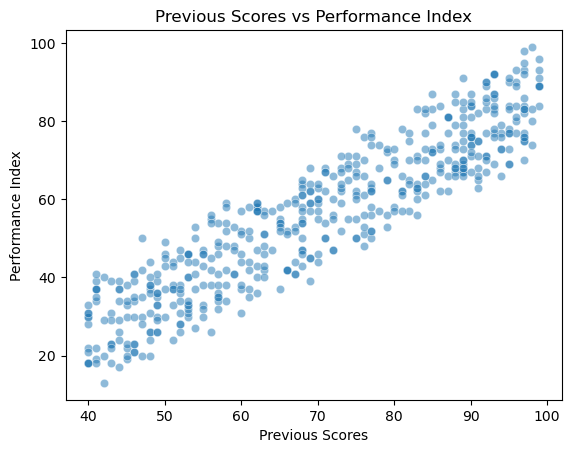

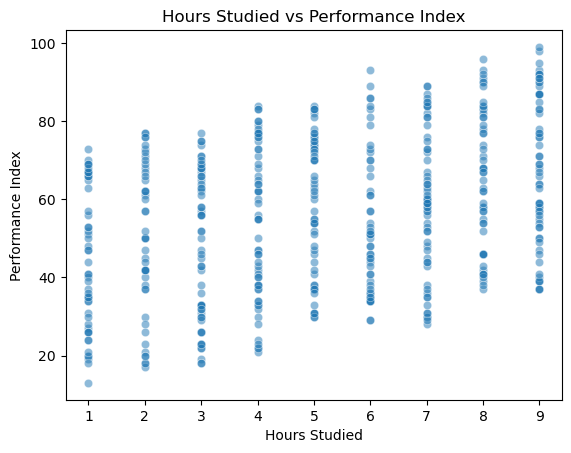

In [13]:
sample =dataset.sample(500,random_state=42)
sns.scatterplot(data=sample,x="Previous Scores", y="Performance Index",alpha=0.5)
plt.title("Previous Scores vs Performance Index")
plt.show()

sns.scatterplot(data=sample,x="Hours Studied",y="Performance Index",alpha=0.5)
plt.title("Hours Studied vs Performance Index")
plt.show()

   - `Previous Scores`: the points form a clear upward, roughly straight cloud, so a linear model fits this feature well.
   - `Hours Studied`: the points form 9 vertical columns (the feature is a whole number from 1 to 9). There is an upward trend, but a wide spread inside each column, which matches the weaker correlation (r = 0.38).

### Mean Performance Index by Hours Studied

`Hours Studied` has only 9 distinct values, so grouping by value is easier to read than a scatter plot.

In [14]:
dataset.groupby("Hours Studied")["Performance Index"].mean()

Hours Studied
1    43.977052
2    46.454039
3    49.763063
4    52.781513
5    55.497661
6    58.483957
7    60.223614
8    64.183426
9    65.807097
Name: Performance Index, dtype: float64

The mean rises at every step, from about 44 (1 hour) to about 66 (9 hours), roughly +2.7 points per extra hour on average. This supports a roughly linear relationship.

### Extracurricular Activities

This column is categorical (Yes/No), so I compare the mean target in each group and plot the distributions.

Extracurricular Activities
No     54.720818
Yes    55.722529
Name: Performance Index, dtype: float64


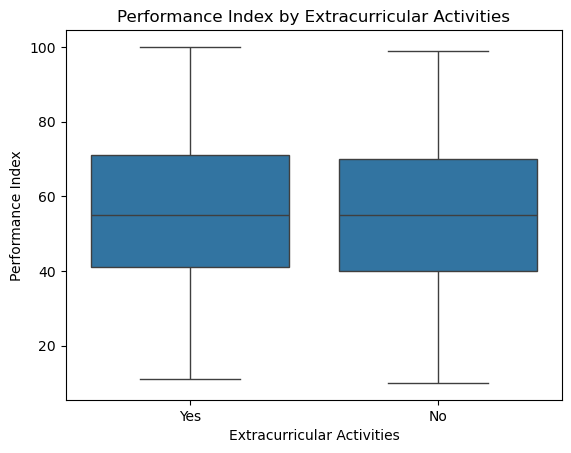

In [15]:
print(dataset.groupby("Extracurricular Activities")["Performance Index"].mean())
sns.boxplot(data=dataset,x="Extracurricular Activities",y="Performance Index")
plt.title("Performance Index by Extracurricular Activities")
plt.show()

The mean `Performance Index` is 55.72 with extracurricular activities and 54.72 without, a difference of only about 1 point. The boxplots overlap almost completely and the medians look similar, so this feature seems weakly related to the target.

### Correlation between features

If two features are strongly correlated with each other (for example above 0.8), regression coefficients can become unstable (multicollinearity). I check the features without the target.

In [16]:
dataset.drop(columns="Performance Index").corr(numeric_only=True)

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced
Hours Studied,1.000000,-0.010676,0.002131,0.015740
Previous Scores,-0.010676,1.000000,0.007975,0.008719
Sleep Hours,0.002131,0.007975,1.000000,0.004907
Sample Question Papers Practiced,0.015740,0.008719,0.004907,1.000000


All correlations between features are below 0.02 in absolute value (the largest is `Hours Studied` and `Sample Question Papers Practiced`, r = 0.016). Multicollinearity is not a concern.

### Conclusion

- Most correlated with `Performance Index`: `Previous Scores` (r = 0.92). Least correlated: `Sample Question Papers Practiced` (r = 0.04).
- `Hours Studied` is a moderate predictor (r = 0.38), about +2.7 points per extra hour.
- `Sleep Hours` (r = 0.05) and `Extracurricular Activities` (about 1 point difference) look weak. A weak correlation alone does not make a feature useless in a multiple regression, so I will check their coefficients later.
- The features are almost uncorrelated with each other, so there is no multicollinearity problem.
- Next step: encode `Extracurricular Activities` and split the data into train and test sets.

In [17]:
X=dataset.iloc[:,0:-1].values
y=dataset.iloc[:,-1].values
print(X)

[[7 99 'Yes' 9 1]
 [4 82 'No' 4 2]
 [8 51 'Yes' 7 2]
 ...
 [6 83 'Yes' 8 5]
 [9 97 'Yes' 7 0]
 [7 74 'No' 8 1]]


   ## Encoding the Categorical Feature

   Linear regression needs numbers, so `Extracurricular Activities` (Yes/No) is converted with One-Hot Encoding. I drop the first category (`drop='first'`) to avoid the dummy variable trap: the columns "No" and "Yes" would always sum to 1, so one of them is redundant. After encoding, the new column is 1 for "Yes" and 0 for "No".

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
ct=ColumnTransformer(transformers=[('encoder',OneHotEncoder(drop='first'),[2])],remainder='passthrough')
X=np.array(ct.fit_transform(X))
X=X.astype(float)
print(X)

[[ 1.  7. 99.  9.  1.]
 [ 0.  4. 82.  4.  2.]
 [ 1.  8. 51.  7.  2.]
 ...
 [ 1.  6. 83.  8.  5.]
 [ 1.  9. 97.  7.  0.]
 [ 0.  7. 74.  8.  1.]]


   ## Train/Test Split

   I use 80% of the data for training and 20% for testing (`random_state` fixed for reproducibility): 7,898 rows for training and 1,975 for testing. The test set stays untouched until the final evaluation.

In [20]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(7898, 5) (1975, 5)
(7898,) (1975,)


In [21]:
from sklearn.linear_model import LinearRegression
regressor=LinearRegression()
regressor.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [31]:
y_pred=regressor.predict(X_test)
print(np.concatenate((y_test.reshape(len(y_test),1),y_pred.reshape(len(y_pred),1)),1))

[[47.         46.48001281]
 [76.         80.2853795 ]
 [62.         61.06518835]
 ...
 [77.         77.08443628]
 [88.         86.24676576]
 [34.         35.8793377 ]]


In [32]:
print(regressor.coef_)
print(regressor.intercept_)

[0.57382297 2.8510219  1.01843034 0.47207329 0.18870366]
-33.98132449644051
